# PISA 2022 — Machine Learning & Clustering

## Project A: Where Should a Ministry Spend?

### Research Questions

RQ3: Do Linear Regression and Random Forest agree?

RQ4: Do countries cluster into recognizable school-system types?

### Countries

Germany, France, Poland, Estonia, Italy, Spain, Ukraine.

In [1]:
from pathlib import Path
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
df = pd.read_parquet(root / "data/processed/pisa_cleaned_dataset.parquet")
print(df.shape)

(121564, 111)


In [2]:
print(df["CNT"].value_counts().sort_index())

CNT
AUT     6151
BEL     8286
CZE     8460
DEU     6116
ESP    30800
EST     6392
FIN    10239
FRA     6770
ITA    10552
NLD     5046
POL     6011
PRT     6793
QUR     3876
SWE     6072
Name: count, dtype: int64


In [3]:
required_countries = [
    "DEU", "FRA", "POL", "EST",
    "ITA", "ESP", "QUR"
]

df_project = df[df["CNT"].isin(required_countries)].copy()

print(df_project.shape)
print(df_project["CNT"].value_counts().sort_index())

(70517, 111)
CNT
DEU     6116
ESP    30800
EST     6392
FRA     6770
ITA    10552
POL     6011
QUR     3876
Name: count, dtype: int64


In [4]:
required_columns = [
    "CNT",
    "CNTSCHID",
    "ESCS",
    "SCH_ESCS",
    "CLSIZE",
    "EDUSHORT",
    "STAFFSHORT",
    "W_FSTUWT"
]

required_columns += [f"PV{i}MATH" for i in range(1, 11)]

for col in required_columns:
    print(col, ":", col in df_project.columns)

CNT : True
CNTSCHID : True
ESCS : True
SCH_ESCS : True
CLSIZE : True
EDUSHORT : True
STAFFSHORT : True
W_FSTUWT : True
PV1MATH : True
PV2MATH : True
PV3MATH : True
PV4MATH : True
PV5MATH : True
PV6MATH : True
PV7MATH : True
PV8MATH : True
PV9MATH : True
PV10MATH : True


In [5]:
missing_count = df_project[required_columns].isna().sum()

missing_percent = (
    df_project[required_columns].isna().mean() * 100
)

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing %": missing_percent.round(2)
})

print(missing_summary)

            Missing Count  Missing %
CNT                     0        0.0
CNTSCHID                0        0.0
ESCS                    0        0.0
SCH_ESCS                0        0.0
CLSIZE                  0        0.0
EDUSHORT                0        0.0
STAFFSHORT              0        0.0
W_FSTUWT                0        0.0
PV1MATH                 0        0.0
PV2MATH                 0        0.0
PV3MATH                 0        0.0
PV4MATH                 0        0.0
PV5MATH                 0        0.0
PV6MATH                 0        0.0
PV7MATH                 0        0.0
PV8MATH                 0        0.0
PV9MATH                 0        0.0
PV10MATH                0        0.0


In [6]:
print(df_project["W_FSTUWT"].describe())

print(
    "Non-positive weights:",
    (df_project["W_FSTUWT"] <= 0).sum()
)

count    70517.000000
mean        41.670464
std         44.481648
min          1.023810
25%          4.643240
50%         23.834630
75%         69.109820
max        318.405100
Name: W_FSTUWT, dtype: float64
Non-positive weights: 0


In [7]:
print(
    "Unique schools:",
    df_project.groupby(["CNT", "CNTSCHID"]).ngroups
)

Unique schools: 2449


In [8]:
df_project["SCHOOL_ID"] = (
    df_project["CNT"].astype(str)
    + "_"
    + df_project["CNTSCHID"].astype(str)
)

print(df_project[["CNT", "CNTSCHID", "SCHOOL_ID"]].head())
print("Unique school IDs:", df_project["SCHOOL_ID"].nunique())

       CNT    CNTSCHID       SCHOOL_ID
22897  EST  23300149.0  EST_23300149.0
22898  EST  23300171.0  EST_23300171.0
22899  EST  23300075.0  EST_23300075.0
22900  EST  23300194.0  EST_23300194.0
22901  EST  23300079.0  EST_23300079.0
Unique school IDs: 2449


In [9]:
ml_features = [
    "CLSIZE",
    "EDUSHORT",
    "STAFFSHORT",
    "SCH_ESCS",
    "ESCS"
]

plausible_values = [
    f"PV{i}MATH" for i in range(1, 11)
]

print("ML Features:", ml_features)
print("Plausible Values:", plausible_values)

ML Features: ['CLSIZE', 'EDUSHORT', 'STAFFSHORT', 'SCH_ESCS', 'ESCS']
Plausible Values: ['PV1MATH', 'PV2MATH', 'PV3MATH', 'PV4MATH', 'PV5MATH', 'PV6MATH', 'PV7MATH', 'PV8MATH', 'PV9MATH', 'PV10MATH']


In [10]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        df_project,
        groups=df_project["SCHOOL_ID"]
    )
)

train_df = df_project.iloc[train_idx].copy()
test_df = df_project.iloc[test_idx].copy()

print("Training students:", len(train_df))
print("Testing students:", len(test_df))

shared_schools = set(train_df["SCHOOL_ID"]) & set(test_df["SCHOOL_ID"])

print("Schools shared between train and test:", len(shared_schools))

Training students: 56029
Testing students: 14488
Schools shared between train and test: 0


In [11]:
country_split = pd.DataFrame({
    "Training": train_df["CNT"].value_counts(),
    "Testing": test_df["CNT"].value_counts()
}).fillna(0).astype(int).sort_index()

print(country_split)

     Training  Testing
CNT                   
DEU      4844     1272
ESP     24694     6106
EST      4995     1397
FRA      5485     1285
ITA      7956     2596
POL      4820     1191
QUR      3235      641


In [12]:
X_train = train_df[ml_features].copy()
X_test = test_df[ml_features].copy()

y_train = train_df[plausible_values].copy()
y_test = test_df[plausible_values].copy()

weights_train = train_df["W_FSTUWT"].copy()
weights_test = test_df["W_FSTUWT"].copy()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (56029, 5)
X_test: (14488, 5)
y_train: (56029, 10)
y_test: (14488, 10)


In [13]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train["PV1MATH"],
    sample_weight=weights_train
)

print("First Random Forest model trained successfully")

First Random Forest model trained successfully


In [14]:
from sklearn.metrics import mean_absolute_error, r2_score

predictions = rf_model.predict(X_test)

mae = mean_absolute_error(
    y_test["PV1MATH"],
    predictions,
    sample_weight=weights_test
)

r2 = r2_score(
    y_test["PV1MATH"],
    predictions,
    sample_weight=weights_test
)

print("Weighted MAE:", round(mae, 2))
print("Weighted R2:", round(r2, 4))

Weighted MAE: 62.63
Weighted R2: 0.2449


In [15]:
rf_results = []

for pv in plausible_values:
    model = RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train,
        y_train[pv],
        sample_weight=weights_train
    )

    predictions = model.predict(X_test)

    mae = mean_absolute_error(
        y_test[pv],
        predictions,
        sample_weight=weights_test
    )

    r2 = r2_score(
        y_test[pv],
        predictions,
        sample_weight=weights_test
    )

    rf_results.append({
        "Plausible Value": pv,
        "Weighted MAE": mae,
        "Weighted R2": r2
    })

rf_results_df = pd.DataFrame(rf_results)

print(rf_results_df.round(4))

  Plausible Value  Weighted MAE  Weighted R2
0         PV1MATH       62.6312       0.2449
1         PV2MATH       62.9175       0.2362
2         PV3MATH       62.3784       0.2360
3         PV4MATH       61.8075       0.2423
4         PV5MATH       62.3698       0.2404
5         PV6MATH       62.5719       0.2340
6         PV7MATH       62.7886       0.2364
7         PV8MATH       62.5379       0.2402
8         PV9MATH       62.7517       0.2334
9        PV10MATH       62.1765       0.2371


In [16]:
rf_summary = rf_results_df[
    ["Weighted MAE", "Weighted R2"]
].mean()

print("Random Forest Summary")
print(rf_summary.round(4))

Random Forest Summary
Weighted MAE    62.4931
Weighted R2      0.2381
dtype: float64


In [17]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(
    X_train,
    y_train["PV1MATH"],
    sample_weight=weights_train
)

print("Linear Regression trained successfully")

Linear Regression trained successfully


In [18]:
lr_predictions = lr_model.predict(X_test)

lr_mae = mean_absolute_error(
    y_test["PV1MATH"],
    lr_predictions,
    sample_weight=weights_test
)

lr_r2 = r2_score(
    y_test["PV1MATH"],
    lr_predictions,
    sample_weight=weights_test
)

print("Linear Regression Weighted MAE:", round(lr_mae, 2))
print("Linear Regression Weighted R2:", round(lr_r2, 4))

Linear Regression Weighted MAE: 61.25
Linear Regression Weighted R2: 0.2791


In [19]:
lr_results = []

for pv in plausible_values:
    model = LinearRegression()

    model.fit(
        X_train,
        y_train[pv],
        sample_weight=weights_train
    )

    predictions = model.predict(X_test)

    mae = mean_absolute_error(
        y_test[pv],
        predictions,
        sample_weight=weights_test
    )

    r2 = r2_score(
        y_test[pv],
        predictions,
        sample_weight=weights_test
    )

    lr_results.append({
        "Plausible Value": pv,
        "Weighted MAE": mae,
        "Weighted R2": r2
    })

lr_results_df = pd.DataFrame(lr_results)

print(lr_results_df.round(4))

  Plausible Value  Weighted MAE  Weighted R2
0         PV1MATH       61.2542       0.2791
1         PV2MATH       61.2918       0.2788
2         PV3MATH       60.7100       0.2763
3         PV4MATH       60.2581       0.2827
4         PV5MATH       60.7655       0.2787
5         PV6MATH       60.9679       0.2749
6         PV7MATH       61.1266       0.2783
7         PV8MATH       61.0396       0.2793
8         PV9MATH       60.8800       0.2791
9        PV10MATH       60.4696       0.2754


In [20]:
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "Mean Weighted MAE": [
        lr_results_df["Weighted MAE"].mean(),
        rf_results_df["Weighted MAE"].mean()
    ],
    "Mean Weighted R2": [
        lr_results_df["Weighted R2"].mean(),
        rf_results_df["Weighted R2"].mean()
    ]
})

print(model_comparison.round(4))

               Model  Mean Weighted MAE  Mean Weighted R2
0  Linear Regression            60.8763            0.2783
1      Random Forest            62.4931            0.2381


In [21]:
rf_importances = []

for pv in plausible_values:
    model = RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train,
        y_train[pv],
        sample_weight=weights_train
    )

    rf_importances.append(model.feature_importances_)

rf_importance_df = pd.DataFrame(
    rf_importances,
    columns=ml_features
)

print(
    rf_importance_df.mean()
    .sort_values(ascending=False)
    .round(4)
)

SCH_ESCS      0.4877
ESCS          0.3115
STAFFSHORT    0.0986
EDUSHORT      0.0709
CLSIZE        0.0314
dtype: float64


In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

lr_coefficients = []

for pv in plausible_values:
    model = LinearRegression()

    model.fit(
        X_train_scaled,
        y_train[pv],
        sample_weight=weights_train
    )

    lr_coefficients.append(model.coef_)

lr_coef_df = pd.DataFrame(
    lr_coefficients,
    columns=ml_features
)

print(lr_coef_df.mean().sort_values(key=abs, ascending=False).round(4))

SCH_ESCS      36.3389
ESCS          16.4591
STAFFSHORT    -3.2566
CLSIZE         3.1449
EDUSHORT       1.0689
dtype: float64


In [23]:
model_comparison.to_csv(
    "RQ3_model_comparison.csv",
    index=False
)

rf_importance_df.mean().to_csv(
    "RQ3_random_forest_importance.csv",
    header=["Mean Importance"]
)

lr_coef_df.mean().to_csv(
    "RQ3_linear_regression_coefficients.csv",
    header=["Mean Coefficient"]
)

print("RQ3 results saved successfully")

RQ3 results saved successfully


In [24]:
cluster_features = [
    "CLSIZE",
    "EDUSHORT",
    "STAFFSHORT",
    "SCH_ESCS"
]

country_summary = df_project.groupby("CNT")[cluster_features].mean()

print(country_summary.round(4))
print("Number of countries:", len(country_summary))

      CLSIZE  EDUSHORT  STAFFSHORT  SCH_ESCS
CNT                                         
DEU  24.4192   -0.0778      0.4127   -0.1495
ESP  25.5308   -0.2717      0.0189    0.0209
EST  23.1134   -0.1205      0.2833    0.1821
FRA  29.2917   -0.3636      0.6218   -0.0679
ITA  22.4404   -0.3493      0.4309   -0.0985
POL  28.7528   -0.3617     -0.5494   -0.0730
QUR  25.2020    0.8922     -0.1375   -0.2849
Number of countries: 7


In [25]:
import numpy as np

country_summary = df_project.groupby("CNT").apply(
    lambda group: pd.Series({
        feature: np.average(
            group[feature],
            weights=group["W_FSTUWT"]
        )
        for feature in cluster_features
    }),
    include_groups=False
)

print(country_summary.round(4))
print("Number of countries:", len(country_summary))

      CLSIZE  EDUSHORT  STAFFSHORT  SCH_ESCS
CNT                                         
DEU  24.3095   -0.0674      0.4269   -0.1650
ESP  25.7641   -0.2930     -0.0497   -0.0164
EST  22.4649   -0.1284      0.2833    0.1490
FRA  29.3565   -0.3863      0.6074   -0.0057
ITA  23.8607   -0.2108      0.5232   -0.0992
POL  28.2794   -0.3661     -0.5224   -0.1103
QUR  24.6894    0.9093     -0.1132   -0.3391
Number of countries: 7


In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_countries = scaler.fit_transform(country_summary)

print("Scaled data shape:", scaled_countries.shape)
print("Scaled means:", scaled_countries.mean(axis=0).round(4))

Scaled data shape: (7, 4)
Scaled means: [-0. -0. -0. -0.]


In [27]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 5):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(scaled_countries)

    score = silhouette_score(scaled_countries, labels)

    print(
        "Clusters:", k,
        "Silhouette Score:", round(score, 4)
    )

Clusters: 2 Silhouette Score: 0.3161
Clusters: 3 Silhouette Score: 0.2048
Clusters: 4 Silhouette Score: 0.2295


In [28]:
model_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

labels_2 = model_2.fit_predict(scaled_countries)

clusters_2 = country_summary.copy()
clusters_2["Cluster"] = labels_2

print(clusters_2["Cluster"].sort_values())

print("\nCluster sizes:")
print(clusters_2["Cluster"].value_counts().sort_index())

CNT
DEU    0
ESP    0
EST    0
FRA    0
ITA    0
POL    0
QUR    1
Name: Cluster, dtype: int32

Cluster sizes:
Cluster
0    6
1    1
Name: count, dtype: int64


In [29]:
model_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

labels_3 = model_3.fit_predict(scaled_countries)

clusters_3 = country_summary.copy()
clusters_3["Cluster"] = labels_3

print(clusters_3["Cluster"].sort_values())

print("\nCluster sizes:")
print(clusters_3["Cluster"].value_counts().sort_index())

CNT
DEU    0
EST    0
ITA    0
ESP    1
FRA    1
POL    1
QUR    2
Name: Cluster, dtype: int32

Cluster sizes:
Cluster
0    3
1    3
2    1
Name: count, dtype: int64


In [30]:
cluster_profiles_3 = (
    clusters_3
    .groupby("Cluster")[cluster_features]
    .mean()
)

print(cluster_profiles_3.round(3))

         CLSIZE  EDUSHORT  STAFFSHORT  SCH_ESCS
Cluster                                        
0        23.545    -0.136       0.411    -0.038
1        27.800    -0.348       0.012    -0.044
2        24.689     0.909      -0.113    -0.339


In [31]:
cluster_profiles_2 = (
    clusters_2
    .groupby("Cluster")[cluster_features]
    .mean()
)

print(cluster_profiles_2.round(3))

         CLSIZE  EDUSHORT  STAFFSHORT  SCH_ESCS
Cluster                                        
0        25.673    -0.242       0.211    -0.041
1        24.689     0.909      -0.113    -0.339


In [32]:
countries_without_ukraine = country_summary.drop(index="QUR")

scaler_6 = StandardScaler()
scaled_6 = scaler_6.fit_transform(countries_without_ukraine)

model_6 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

labels_6 = model_6.fit_predict(scaled_6)

score_6 = silhouette_score(scaled_6, labels_6)

print("Silhouette Score:", round(score_6, 4))

print(
    pd.Series(
        labels_6,
        index=countries_without_ukraine.index
    ).sort_values()
)

Silhouette Score: 0.2524
CNT
DEU    0
EST    0
ITA    0
ESP    1
FRA    1
POL    1
dtype: int32


In [33]:
clusters_6 = countries_without_ukraine.copy()

clusters_6["Cluster"] = labels_6

profiles_6 = (
    clusters_6
    .groupby("Cluster")[cluster_features]
    .mean()
)

print(profiles_6.round(3))

         CLSIZE  EDUSHORT  STAFFSHORT  SCH_ESCS
Cluster                                        
0        23.545    -0.136       0.411    -0.038
1        27.800    -0.348       0.012    -0.044


In [34]:
country_names = {
    "DEU": "Germany",
    "FRA": "France",
    "POL": "Poland",
    "EST": "Estonia",
    "ITA": "Italy",
    "ESP": "Spain",
    "QUR": "Ukraine (18 of 27 regions)"
}

rq4_results = clusters_3.copy()

rq4_results.index = rq4_results.index.map(country_names)

rq4_results.index.name = "Country"

print(rq4_results.round(3))

                            CLSIZE  EDUSHORT  STAFFSHORT  SCH_ESCS  Cluster
Country                                                                    
Germany                     24.309    -0.067       0.427    -0.165        0
Spain                       25.764    -0.293      -0.050    -0.016        1
Estonia                     22.465    -0.128       0.283     0.149        0
France                      29.356    -0.386       0.607    -0.006        1
Italy                       23.861    -0.211       0.523    -0.099        0
Poland                      28.279    -0.366      -0.522    -0.110        1
Ukraine (18 of 27 regions)  24.689     0.909      -0.113    -0.339        2


In [35]:
rq4_results.to_csv(
    "RQ4_country_clusters.csv",
    index=True
)

print("RQ4 results saved successfully")

RQ4 results saved successfully


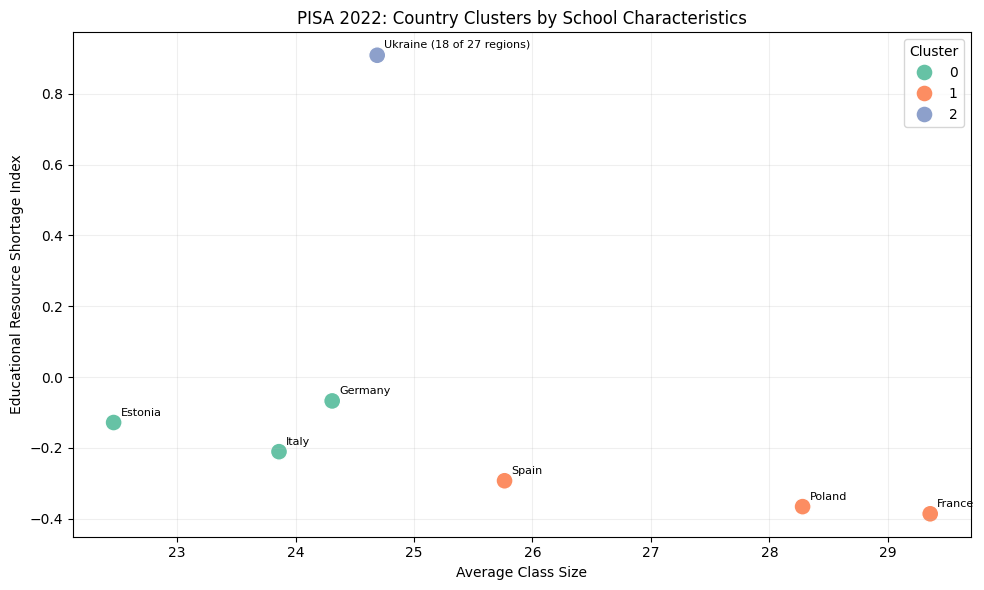

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rq4_results,
    x="CLSIZE",
    y="EDUSHORT",
    hue="Cluster",
    palette="Set2",
    s=150
)

for country, row in rq4_results.iterrows():
    plt.annotate(
        country,
        (row["CLSIZE"], row["EDUSHORT"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title("PISA 2022: Country Clusters by School Characteristics")
plt.xlabel("Average Class Size")
plt.ylabel("Educational Resource Shortage Index")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("RQ4_country_clusters.png", dpi=300, bbox_inches="tight")
plt.show()

## Results Interpretation and Limitations

### RQ3: Linear Regression vs Random Forest

We compared Linear Regression and Random Forest models to predict PISA 2022 mathematics performance using school characteristics and socioeconomic indicators across seven countries.

Both models were evaluated using a school-level train-test split to prevent students from the same school appearing in both sets. Student sampling weights were incorporated, and model performance was evaluated separately across all ten mathematics plausible values.

**Results:**

| Model | Mean Weighted MAE | Mean Weighted R² |
|---|---:|---:|
| Linear Regression | 60.88 | 0.2783 |
| Random Forest | 62.49 | 0.2381 |

Linear Regression performed better than Random Forest, achieving lower prediction errors and higher R² values on the test data.

The Random Forest feature importance analysis identified school-level socioeconomic status (SCH_ESCS) and individual socioeconomic status (ESCS) as the strongest predictors.

**Limitations:** These findings describe predictive associations rather than causal effects. Model performance depends on the selected variables, model settings, and data split. Averaging performance across plausible values does not fully account for the complex PISA survey design or its associated uncertainty.


### RQ4: Country Clustering

We applied K-Means clustering to examine whether the seven selected countries could be grouped into recognizable school-system types based on four characteristics: average class size (CLSIZE), educational resource shortages (EDUSHORT), staff shortages (STAFFSHORT), and school-level socioeconomic status (SCH_ESCS).

Country-level averages were calculated using student sampling weights, and the four features were standardized before clustering.

We compared solutions with two, three, and four clusters using the silhouette score.

| Number of Clusters | Silhouette Score |
|---|---:|
| 2 | 0.3161 |
| 3 | 0.2048 |
| 4 | 0.2295 |

The two-cluster solution achieved the highest silhouette score but separated Ukraine from the other six countries.

The three-cluster solution provided a more detailed descriptive grouping:

- **Cluster 0:** Germany, Estonia, and Italy.
- **Cluster 1:** Spain, France, and Poland.
- **Cluster 2:** Ukraine (18 of 27 regions).

As a sensitivity analysis, we repeated the two-cluster analysis after excluding Ukraine. The remaining six countries formed two groups, with a silhouette score of 0.2524.

**Limitations:** The analysis included only seven countries, and Ukraine's PISA 2022 data covered 18 of its 27 regions. Cluster assignments are sensitive to the selected variables and countries. The relatively low silhouette scores suggest that these results should be interpreted as exploratory groupings rather than definitive school-system categories. The analysis does not establish causal relationships or identify optimal education spending policies.